# Лабораторная работа №2. Regularization и KNN

**Дисциплина:** «Системы искусственного интеллекта»

**Часть A.** Regularization в моделях из лабораторной №1: Linear Regression на [Bike Sharing Dataset](https://www.kaggle.com/datasets/marklvl/bike-sharing-dataset) и Logistic Regression на [Spaceship Titanic](https://www.kaggle.com/competitions/spaceship-titanic).

**Часть B.** KNN Classification, датасет [Dry Bean Dataset](https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset), целевая переменная `Class`.

**Часть C.** KNN Regression, датасет [Seoul Bike Sharing Demand](https://www.kaggle.com/datasets/joebeachcapital/seoul-bike-sharing), целевая переменная `Rented Bike Count`.

Модели реализованы вручную на PyTorch. В части A градиент функции потерь считает `autograd`, градиент штрафа добавляется к нему явно, обновление весов выполняется вручную. KNN считает расстояния, выбирает соседей и голосует собственным кодом. Готовые модели, `torch.nn`, `torch.optim`, split и scaler из sklearn не используются, из `sklearn.metrics` берутся только метрики. PyTorch, как и в лабораторной №1, используется вместо NumPy для операций с массивами и для `autograd`.

### Содержание
1. Настройка окружения и общие функции
2. Часть A. Regularization: данные, модели, подбор λ, сравнение, вывод
3. Часть B. KNN Classification: данные, класс KNN, подбор k, scaling, метрики, вывод
4. Часть C. KNN Regression: данные, подбор k, scaling, baseline, вывод
5. Выводы

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss, confusion_matrix

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 200)

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.titleweight'] = 'bold'

RANDOM_STATE = 23
torch.manual_seed(RANDOM_STATE)
DTYPE = torch.float32

## Общие функции

Split из лабораторной №1 расширен до трёх частей: train `60%`, validation `20%`, test `20%`. Validation нужен для подбора λ и k, test используется один раз для итоговой оценки.

Стандартизация считает среднее и стандартное отклонение только по train и применяет их к validation и test, чтобы не было `data leakage`. Функция `evaluate_reg` считает MAE, RMSE и R² для частей A и C.

In [2]:
def train_val_test_split(X, y, val_size=0.2, test_size=0.2, seed=RANDOM_STATE):
    generator = torch.Generator().manual_seed(seed)
    idx = torch.randperm(X.shape[0], generator=generator) # случайная перестановка индексов объектов [0, n-1]
    n_test = int(X.shape[0] * test_size)
    n_val = int(X.shape[0] * val_size)
    test_idx, val_idx, train_idx = idx[:n_test], idx[n_test:n_test + n_val], idx[n_test + n_val:]
    return X[train_idx], X[val_idx], X[test_idx], y[train_idx], y[val_idx], y[test_idx]


def standardize(X_train, X_val, X_test, cols):
    mean = X_train[:, cols].mean(dim=0)
    std = X_train[:, cols].std(dim=0)
    scaled = []
    for X in (X_train, X_val, X_test):
        X_s = X.clone()
        X_s[:, cols] = (X[:, cols] - mean) / std
        scaled.append(X_s)
    return scaled


def evaluate_reg(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
        'R2': r2_score(y_true, y_pred),
    }

# Часть A. Regularization

Обе модели и preprocessing взяты из лабораторной №1. Данные читаются из папки `lab1`.

## Данные и preprocessing из лабораторной №1

### Linear Regression, Bike Sharing

Целевая переменная `cnt`. Удалены `casual` и `registered`, потому что `cnt = casual + registered`, а также `instant` и `dteday`. Категориальные `season`, `mnth`, `weekday`, `weathersit` закодированы one-hot, вещественные `temp`, `atemp`, `hum`, `windspeed` стандартизированы по train.

Отличие от лабораторной №1: целевая переменная тоже стандартизирована по train. Без этого MSE измеряется в миллионах, веса в сотнях, и λ для линейной и логистической регрессии пришлось бы подбирать на разных шкалах. Метрики считаются после обратного преобразования прогноза в число поездок.

In [3]:
df_a = pd.read_csv('../lab1/data_part_A/day.csv')

y_a = df_a['cnt']
X_a = df_a.drop(columns=['instant', 'dteday', 'casual', 'registered', 'cnt'])
X_a = pd.get_dummies(X_a, columns=['season', 'mnth', 'weekday', 'weathersit'], drop_first=True, dtype=float)
feature_names_a = X_a.columns.tolist()

X_train_a, X_val_a, X_test_a, y_train_a, y_val_a, y_test_a = train_val_test_split(
    torch.tensor(X_a.values, dtype=DTYPE), torch.tensor(y_a.values, dtype=DTYPE))

num_idx_a = [feature_names_a.index(c) for c in ['temp', 'atemp', 'hum', 'windspeed']]
X_train_a_s, X_val_a_s, X_test_a_s = standardize(X_train_a, X_val_a, X_test_a, num_idx_a)

y_mean_a, y_std_a = y_train_a.mean(), y_train_a.std()
y_train_a_s = (y_train_a - y_mean_a) / y_std_a
y_val_a_s = (y_val_a - y_mean_a) / y_std_a

print(f'Количество признаков: {X_a.shape[1]}')
print(f'Количество объектов: train {X_train_a.shape[0]}, validation {X_val_a.shape[0]}, test {X_test_a.shape[0]}')

Количество признаков: 29
Количество объектов: train 439, validation 146, test 146


### Logistic Regression, Spaceship Titanic

Целевая переменная `Transported`. Удалены `PassengerId` и `Name`, `Cabin` разбит на палубу `Deck` и сторону `Side`. Пропуски в категориальных признаках заменены категорией `Unknown`, после этого one-hot. Пропуски в `Age` и тратах заполнены медианой по train, затем стандартизация по train.

In [4]:
df_ab = pd.read_csv('../lab1/data_part_B/train.csv')

SPEND_COLS = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
REAL_COLS_B = ['Age'] + SPEND_COLS
CAT_COLS_B = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'Side']

y_ab = df_ab['Transported'].astype(float)
X_ab = df_ab.drop(columns=['PassengerId', 'Name', 'Transported'])
X_ab[['Deck', 'Side']] = X_ab['Cabin'].str.split('/', expand=True)[[0, 2]]
X_ab = X_ab.drop(columns='Cabin')
for c in CAT_COLS_B:
    X_ab[c] = X_ab[c].astype(object).fillna('Unknown').astype(str)
X_ab = pd.get_dummies(X_ab, columns=CAT_COLS_B, drop_first=True, dtype=float)
feature_names_ab = X_ab.columns.tolist()

X_train_ab, X_val_ab, X_test_ab, y_train_ab, y_val_ab, y_test_ab = train_val_test_split(
    torch.tensor(X_ab.values, dtype=DTYPE), torch.tensor(y_ab.values, dtype=DTYPE))

num_idx_ab = [feature_names_ab.index(c) for c in REAL_COLS_B]
train_median_ab = torch.nanmedian(X_train_ab[:, num_idx_ab], dim=0).values
for X in (X_train_ab, X_val_ab, X_test_ab):
    X[:, num_idx_ab] = torch.where(torch.isnan(X[:, num_idx_ab]), train_median_ab, X[:, num_idx_ab]) # медиана train вместо NaN
X_train_ab_s, X_val_ab_s, X_test_ab_s = standardize(X_train_ab, X_val_ab, X_test_ab, num_idx_ab)

print(f'Количество признаков: {X_ab.shape[1]}')
print(f'Количество объектов: train {X_train_ab.shape[0]}, validation {X_val_ab.shape[0]}, test {X_test_ab.shape[0]}')
print(f'Пропусков после заполнения во всех трёх выборках: {sum(torch.isnan(X).sum().item() for X in (X_train_ab_s, X_val_ab_s, X_test_ab_s))}')

Количество признаков: 26
Количество объектов: train 5217, validation 1738, test 1738
Пропусков после заполнения во всех трёх выборках: 0


## 1-2. Штрафы и изменение градиента

К функции потерь из лабораторной №1 добавляется штраф на веса `w`. Свободный коэффициент `b` не штрафуется, он отвечает за средний уровень целевой переменной.

| Вариант | Loss | Добавка к градиенту по `w` |
|---|---|---|
| без регуляризации | $L$ | $0$ |
| L1 | $L + \lambda \sum_j \lvert w_j \rvert$ | $\lambda \cdot \mathrm{sign}(w)$ |
| L2 | $L + \lambda \sum_j w_j^2$ | $2 \lambda w$ |
| ElasticNet | $L + \lambda \left(\alpha \sum_j \lvert w_j \rvert + (1 - \alpha) \sum_j w_j^2\right)$ | $\lambda \left(\alpha \cdot \mathrm{sign}(w) + 2 (1 - \alpha) w\right)$ |

Здесь $L$ - MSE для линейной регрессии и BCE для логистической, $\lambda$ - сила штрафа `lam`, $\alpha$ - доля L1 в ElasticNet `l1_ratio`.

Градиент $L$ считает `autograd`, как в лабораторной №1. Шаг градиентного спуска делает функция `regularized_step`:

1. Шаг по градиенту $L$ плюс градиент L2-части $2 \lambda_2 w$: $z = w - lr \cdot (\nabla L + 2 \lambda_2 w)$.
2. Шаг по градиенту L1-части $\lambda_1 \mathrm{sign}(w)$: вес сдвигается к нулю на $lr \cdot \lambda_1$, но не переходит через ноль: $w = \mathrm{sign}(z) \cdot \max(\lvert z \rvert - lr \cdot \lambda_1, 0)$.

Здесь $\lambda_1$ и $\lambda_2$ - коэффициенты при $\sum \lvert w_j \rvert$ и $\sum w_j^2$. У $\lvert w \rvert$ нет производной в нуле. Если делать обычный шаг $-lr \cdot \lambda_1 \mathrm{sign}(w)$, вес, который должен стать нулём, каждую эпоху перескакивает через ноль и колеблется с амплитудой $lr \cdot \lambda_1$. Обрезка в нуле, она же soft-thresholding, оставляет такой вес ровно нулём. Для ненулевого веса, который не переходит через ноль, шаг совпадает с обычным шагом по градиенту из таблицы.

In [5]:
REGS = ['none', 'l1', 'l2', 'elasticnet']


def penalty_coefs(reg, lam, l1_ratio):
    if reg == 'l1':
        return lam, 0.0
    if reg == 'l2':
        return 0.0, lam
    if reg == 'elasticnet':
        return lam * l1_ratio, lam * (1 - l1_ratio)
    return 0.0, 0.0


def penalty(w, reg, lam, l1_ratio):
    l1, l2 = penalty_coefs(reg, lam, l1_ratio)
    return l1 * w.abs().sum() + l2 * (w ** 2).sum()


def regularized_step(w, grad, lr, reg, lam, l1_ratio):
    l1, l2 = penalty_coefs(reg, lam, l1_ratio)
    z = w - lr * (grad + 2 * l2 * w) # шаг по градиенту loss + градиенту L2
    return torch.sign(z) * torch.clamp(z.abs() - lr * l1, min=0) # шаг L1 к нулю на lr * l1 без перехода через ноль

### Класс LinearRegression с регуляризацией

Новые параметры `reg`, `lam`, `l1_ratio`. В `loss_history` записывается полный loss со штрафом, в `val_loss_history` только MSE на validation, чтобы варианты можно было сравнивать между собой.

In [6]:
class LinearRegression:
    def __init__(self, lr=0.1, n_epochs=2000, reg='none', lam=0.0, l1_ratio=0.5):
        self.lr = lr
        self.n_epochs = n_epochs
        self.reg = reg
        self.lam = lam
        self.l1_ratio = l1_ratio
        self.w = None
        self.b = None
        self.loss_history = []
        self.val_loss_history = []

    def fit(self, X, y, X_val=None, y_val=None):
        self.w = torch.zeros(X.shape[1], dtype=torch.float32, requires_grad=True)
        self.b = torch.zeros(1, dtype=torch.float32, requires_grad=True)
        self.loss_history = []
        self.val_loss_history = []

        for _ in range(self.n_epochs):
            y_pred = X @ self.w + self.b
            loss = ((y_pred - y) ** 2).mean()
            loss.backward() # градиент MSE через autograd

            with torch.no_grad():
                self.loss_history.append(loss.item() + penalty(self.w, self.reg, self.lam, self.l1_ratio).item())
                self.w.copy_(regularized_step(self.w, self.w.grad, self.lr, self.reg, self.lam, self.l1_ratio))
                self.b -= self.lr * self.b.grad # b не штрафуется

            self.w.grad.zero_()
            self.b.grad.zero_()

            if X_val is not None:
                with torch.no_grad():
                    self.val_loss_history.append(((X_val @ self.w + self.b - y_val) ** 2).mean().item())

        return self

    def predict(self, X):
        with torch.no_grad():
            return X @ self.w + self.b

### Класс LogisticRegression с регуляризацией

In [7]:
class LogisticRegression:
    def __init__(self, lr=0.5, n_epochs=2000, threshold=0.5, reg='none', lam=0.0, l1_ratio=0.5):
        self.lr = lr
        self.n_epochs = n_epochs
        self.threshold = threshold
        self.reg = reg
        self.lam = lam
        self.l1_ratio = l1_ratio
        self.w = None
        self.b = None
        self.loss_history = []
        self.val_loss_history = []

    @staticmethod
    def logLoss(p, y, eps=1e-7):
        p = p.clamp(eps, 1 - eps) # чтобы не было log(0)
        return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()

    def fit(self, X, y, X_val=None, y_val=None):
        self.w = torch.zeros(X.shape[1], dtype=torch.float32, requires_grad=True)
        self.b = torch.zeros(1, dtype=torch.float32, requires_grad=True)
        self.loss_history = []
        self.val_loss_history = []

        for _ in range(self.n_epochs):
            loss = self.logLoss(self.forward(X), y)
            loss.backward() # градиент BCE через autograd

            with torch.no_grad():
                self.loss_history.append(loss.item() + penalty(self.w, self.reg, self.lam, self.l1_ratio).item())
                self.w.copy_(regularized_step(self.w, self.w.grad, self.lr, self.reg, self.lam, self.l1_ratio))
                self.b -= self.lr * self.b.grad # b не штрафуется

            self.w.grad.zero_()
            self.b.grad.zero_()

            if X_val is not None:
                with torch.no_grad():
                    self.val_loss_history.append(self.logLoss(self.predict_proba(X_val), y_val).item())
        return self

    def forward(self, X):
        return torch.sigmoid(X @ self.w + self.b)

    def predict_proba(self, X):
        with torch.no_grad():
            return self.forward(X)

    def predict(self, X):
        return (self.predict_proba(X) >= self.threshold).float()

## 3-5. подбор λ по validation

Все варианты обучаются на одном split и одном preprocessing, с одинаковыми `lr`, `n_epochs` и нулевой инициализацией весов. Параметры обучения те же, что в лабораторной №1: `lr=0.1` для линейной регрессии, `lr=0.5` для логистической, `2000` эпох.

| Параметр | Значения |
|---|---|
| `lam` | `1e-4`, `3e-4`, `1e-3`, `3e-3`, `1e-2`, `3e-2`, `0.1`, `0.3`, `1` |
| `l1_ratio` для ElasticNet | `0.2`, `0.5`, `0.8` |
| критерий для линейной регрессии | RMSE на validation в числе поездок, меньше - лучше |
| критерий для логистической регрессии | LogLoss на validation, меньше - лучше |

Test в подборе не участвует.

In [8]:
LAMBDAS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0]
L1_RATIOS = [0.2, 0.5, 0.8]
GRID = ([('none', 0.0, None)]
        + [('l1', lam, None) for lam in LAMBDAS]
        + [('l2', lam, None) for lam in LAMBDAS]
        + [('elasticnet', lam, r) for r in L1_RATIOS for lam in LAMBDAS])


def grid_search(model_cls, params, X_tr, y_tr, X_val, y_val, score_fn):
    rows = []
    for reg, lam, r in GRID:
        model = model_cls(**params, reg=reg, lam=lam, l1_ratio=r if r is not None else 0.5)
        model.fit(X_tr, y_tr, X_val, y_val)
        rows.append({'reg': reg, 'lam': lam, 'l1_ratio': r, 'val_score': score_fn(model), 'model': model})
    return pd.DataFrame(rows)


def best_by_reg(res):
    best = res.loc[res.groupby('reg')['val_score'].idxmin()].set_index('reg')
    return best.loc[REGS]

In [9]:
def val_rmse_a(model):
    y_pred = model.predict(X_val_a_s) * y_std_a + y_mean_a # обратно в число поездок
    return mean_squared_error(y_val_a, y_pred) ** 0.5

res_a = grid_search(LinearRegression, {'lr': 0.1, 'n_epochs': 2000},
                    X_train_a_s, y_train_a_s, X_val_a_s, y_val_a_s, val_rmse_a)
best_a = best_by_reg(res_a)
print('Linear Regression, лучший λ каждого варианта по RMSE на validation:')
best_a[['lam', 'l1_ratio', 'val_score']].rename(columns={'val_score': 'RMSE val'}).round(4)

Linear Regression, лучший λ каждого варианта по RMSE на validation:


,lam,l1_ratio,RMSE val
reg,,,
none,0.00,NaN,738.2010
l1,0.01,NaN,721.6579
l2,0.01,NaN,713.1964
elasticnet,0.01,0.2,712.6447


In [10]:
def val_logloss_ab(model):
    return log_loss(y_val_ab, model.predict_proba(X_val_ab_s))

res_ab = grid_search(LogisticRegression, {'lr': 0.5, 'n_epochs': 2000},
                     X_train_ab_s, y_train_ab, X_val_ab_s, y_val_ab, val_logloss_ab)
best_ab = best_by_reg(res_ab)
print('Logistic Regression, лучший λ каждого варианта по LogLoss на validation:')
best_ab[['lam', 'l1_ratio', 'val_score']].rename(columns={'val_score': 'LogLoss val'}).round(4)

Logistic Regression, лучший λ каждого варианта по LogLoss на validation:


,lam,l1_ratio,LogLoss val
reg,,,
none,0.000,NaN,0.4529
l1,0.001,NaN,0.4502
l2,0.001,NaN,0.4517
elasticnet,0.001,0.8,0.4504


## 6. Сравнение 4 вариантов на одном графике

Левый график - метрика на validation в зависимости от λ. Пунктир - модель без регуляризации, для ElasticNet показан лучший `l1_ratio`. Правый график - validation loss по эпохам для лучшего λ каждого варианта. У линейной регрессии без регуляризации MSE на validation примерно после `500`-й эпохи начинает расти, это переобучение. С регуляризацией кривые остаются на минимуме. У логистической регрессии кривые почти совпадают.

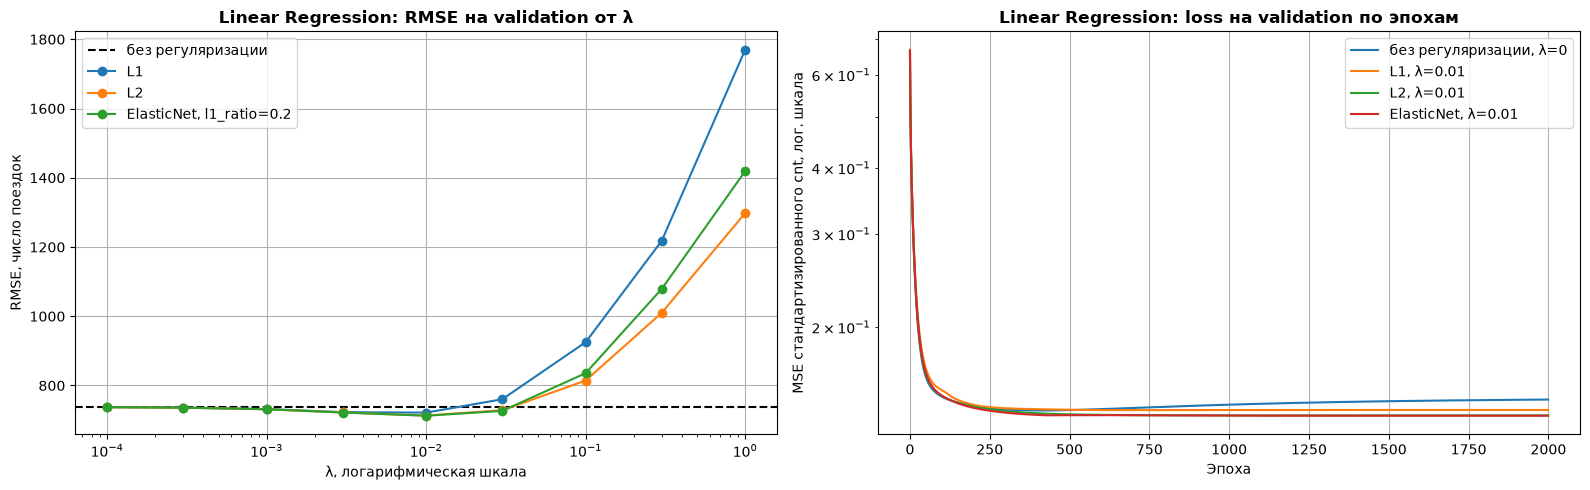

In [11]:
LABELS = {'none': 'без регуляризации', 'l1': 'L1', 'l2': 'L2', 'elasticnet': 'ElasticNet'}


def plot_comparison(res, best, metric, metric_label, loss_label, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    axes[0].axhline(best.loc['none', 'val_score'], color='black', linestyle='--', label=LABELS['none'])
    for reg in ['l1', 'l2', 'elasticnet']:
        part = res[res['reg'] == reg]
        if reg == 'elasticnet':
            r = best.loc[reg, 'l1_ratio']
            part = part[part['l1_ratio'] == r]
            label = f'ElasticNet, l1_ratio={r}'
        else:
            label = LABELS[reg]
        axes[0].plot(part['lam'], part['val_score'], marker='o', label=label)
    axes[0].set_xscale('log')
    axes[0].set_title(f'{title}: {metric} на validation от λ')
    axes[0].set_xlabel('λ, логарифмическая шкала')
    axes[0].set_ylabel(metric_label)
    axes[0].legend()

    for reg in REGS:
        m = best.loc[reg, 'model']
        axes[1].plot(m.val_loss_history, label=f'{LABELS[reg]}, λ={best.loc[reg, "lam"]:g}')
    axes[1].set_yscale('log')
    axes[1].set_title(f'{title}: loss на validation по эпохам')
    axes[1].set_xlabel('Эпоха')
    axes[1].set_ylabel(loss_label)
    axes[1].legend()
    plt.tight_layout()
    plt.show()


plot_comparison(res_a, best_a, 'RMSE', 'RMSE, число поездок', 'MSE стандартизированного cnt, лог. шкала', 'Linear Regression')

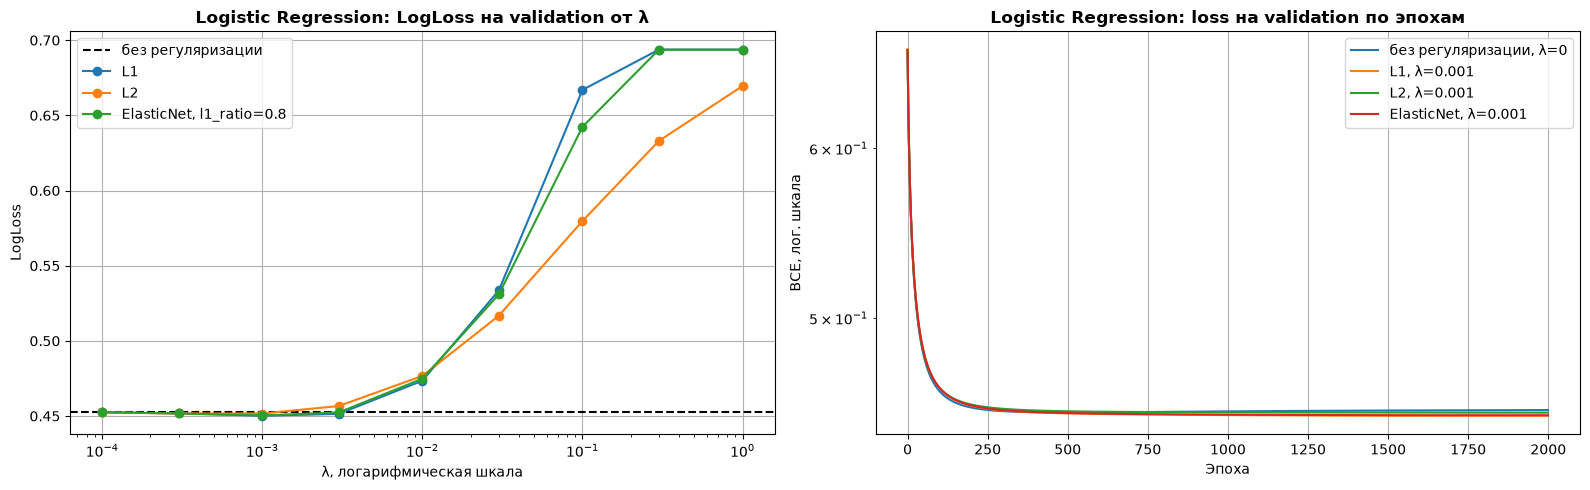

In [12]:
plot_comparison(res_ab, best_ab, 'LogLoss', 'LogLoss', 'BCE, лог. шкала', 'Logistic Regression')

## 7. Таблица итоговых метрик

Каждый вариант обучен на train с λ, выбранным по validation. Метрики на test посчитаны один раз после выбора.

In [13]:
rows_a = {}
for reg in REGS:
    m = best_a.loc[reg, 'model']
    rows_a[LABELS[reg]] = {
        (name, metric): v
        for name, X, y in [('train', X_train_a_s, y_train_a), ('val', X_val_a_s, y_val_a), ('test', X_test_a_s, y_test_a)]
        for metric, v in evaluate_reg(y, m.predict(X) * y_std_a + y_mean_a).items()
    }
metrics_a = pd.DataFrame(rows_a).T
print('Linear Regression, MAE и RMSE в числе поездок:')
metrics_a.round({c: 4 if c[1] == 'R2' else 1 for c in metrics_a.columns})

Linear Regression, MAE и RMSE в числе поездок:


train                   val                  test               
                     MAE   RMSE      R2    MAE   RMSE      R2    MAE   RMSE      R2
без регуляризации  549.3  737.5  0.8541  563.5  738.2  0.8493  580.1  870.1  0.8063
L1                 573.1  763.7  0.8436  551.2  721.7  0.8560  590.6  854.0  0.8134
L2                 568.1  757.5  0.8461  548.7  713.2  0.8594  582.6  853.8  0.8135
ElasticNet         568.2  758.5  0.8457  547.1  712.6  0.8596  584.3  854.0  0.8134

In [14]:
def evaluate_cls(y_true, y_pred, y_proba):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'LogLoss': log_loss(y_true, y_proba),
    }


rows_ab = {}
for reg in REGS:
    m = best_ab.loc[reg, 'model']
    for name, X, y in [('train', X_train_ab_s, y_train_ab), ('val', X_val_ab_s, y_val_ab), ('test', X_test_ab_s, y_test_ab)]:
        rows_ab[(LABELS[reg], name)] = evaluate_cls(y, m.predict(X), m.predict_proba(X))
metrics_ab = pd.DataFrame(rows_ab).T
print('Logistic Regression:')
metrics_ab.round(4)

Logistic Regression:


Accuracy  Precision  Recall      F1  LogLoss
без регуляризации train    0.7962     0.7880  0.8220  0.8046   0.4219
                  val      0.7854     0.7720  0.8000  0.7858   0.4529
                  test     0.7808     0.7658  0.8023  0.7836   0.4550
L1                train    0.7968     0.7897  0.8205  0.8048   0.4236
                  val      0.7831     0.7704  0.7965  0.7832   0.4502
                  test     0.7860     0.7717  0.8058  0.7884   0.4515
L2                train    0.7959     0.7931  0.8119  0.8024   0.4256
                  val      0.7831     0.7728  0.7918  0.7822   0.4517
                  test     0.7860     0.7760  0.7977  0.7867   0.4512
ElasticNet        train    0.7955     0.7896  0.8171  0.8031   0.4239
                  val      0.7808     0.7687  0.7930  0.7807   0.4504
                  test     0.7860     0.7735  0.8023  0.7877   0.4511

## 8. Величины весов и почти нулевые коэффициенты

Коэффициент считается почти нулевым, если $\lvert w_j \rvert <$ `1e-2`. Отдельно посчитаны точные нули, которые даёт шаг L1. У линейной регрессии веса измеряются в стандартных отклонениях `cnt`, у логистической - в логитах, поэтому порог для обеих моделей одного порядка.

In [15]:
EPS = 1e-2


def weights_table(best):
    rows = {}
    for reg in REGS:
        w = best.loc[reg, 'model'].w.detach()
        rows[LABELS[reg]] = {
            'λ': best.loc[reg, 'lam'],
            'sum |w|': w.abs().sum().item(),
            'sqrt(sum w^2)': w.norm().item(),
            'max |w|': w.abs().max().item(),
            f'|w| < {EPS}': int((w.abs() < EPS).sum().item()),
            'w = 0': int((w == 0).sum().item()),
        }
    return pd.DataFrame.from_dict(rows, orient='index')


print(f'Linear Regression, всего весов: {len(feature_names_a)}')
weights_table(best_a).round(4)

Linear Regression, всего весов: 29


,λ,sum |w|,sqrt(sum w^2),max |w|,|w| < 0.01,w = 0
без регуляризации,0.00,8.0853,2.2289,1.1817,0,0
L1,0.01,5.4764,1.7559,1.0200,12,12
L2,0.01,6.2726,1.7197,1.0008,1,0
ElasticNet,0.01,6.0041,1.7158,1.0046,1,1


In [16]:
print(f'Logistic Regression, всего весов: {len(feature_names_ab)}')
weights_table(best_ab).round(4)

Logistic Regression, всего весов: 26


,λ,sum |w|,sqrt(sum w^2),max |w|,|w| < 0.01,w = 0
без регуляризации,0.000,17.8485,4.8263,2.3834,0,0
L1,0.001,14.4297,4.2736,2.1812,7,7
L2,0.001,13.9622,3.7854,1.8271,1,0
ElasticNet,0.001,14.1674,4.1347,2.0860,7,7


In [17]:
def small_weights(best, names):
    rows = {}
    for reg in REGS:
        w = best.loc[reg, 'model'].w.detach()
        rows[LABELS[reg]] = {
            'w = 0': ', '.join(n for n, wi in zip(names, w) if wi == 0) or '-',
            f'0 < |w| < {EPS}': ', '.join(n for n, wi in zip(names, w) if 0 < wi.abs() < EPS) or '-',
        }
    return pd.DataFrame.from_dict(rows, orient='index')


print('Linear Regression, признаки с нулевыми и почти нулевыми весами:')
small_weights(best_a, feature_names_a)

Linear Regression, признаки с нулевыми и почти нулевыми весами:


,w = 0,0 < |w| < 0.01
без регуляризации,-,-
L1,"holiday, mnth_2, mnth_3, mnth_4, mnth_6, mnth_8, mnth_11, mnth_12, weekday_2, weekday_3, weekday_4, weekday_5",-
L2,-,weekday_5
ElasticNet,weekday_5,-


In [18]:
print('Logistic Regression, признаки с нулевыми и почти нулевыми весами:')
small_weights(best_ab, feature_names_ab)

Logistic Regression, признаки с нулевыми и почти нулевыми весами:


,w = 0,0 < |w| < 0.01
без регуляризации,-,-
L1,"Destination_Unknown, VIP_True, VIP_Unknown, Deck_F, Deck_T, Deck_Unknown, Side_Unknown",-
L2,-,Deck_F
ElasticNet,"Destination_Unknown, VIP_True, VIP_Unknown, Deck_F, Deck_T, Deck_Unknown, Side_Unknown",-


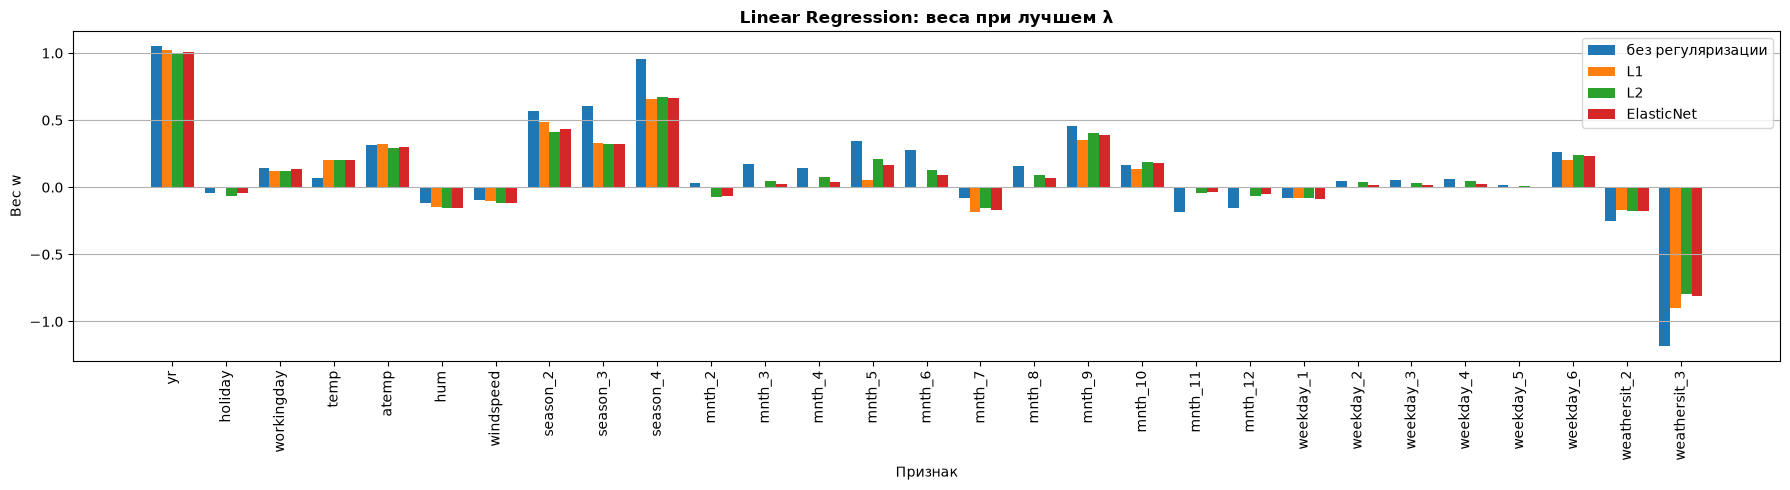

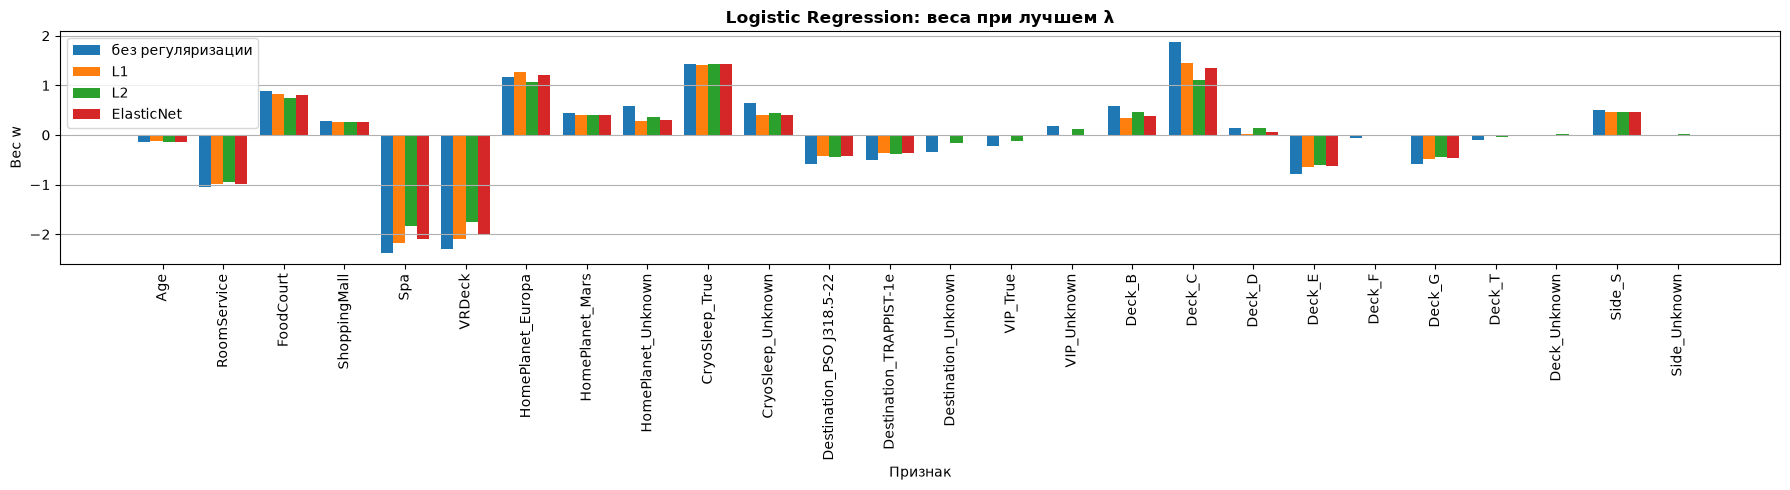

In [19]:
def plot_weights(best, feature_names, title):
    width = 0.2
    x = np.arange(len(feature_names))
    plt.figure(figsize=(18, 5))
    for i, reg in enumerate(REGS):
        plt.bar(x + (i - 1.5) * width, best.loc[reg, 'model'].w.detach().numpy(), width, label=LABELS[reg])
    plt.xticks(x, feature_names, rotation=90)
    plt.grid(False)
    plt.grid(axis='y')
    plt.title(f'{title}: веса при лучшем λ')
    plt.xlabel('Признак')
    plt.ylabel('Вес w')
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_weights(best_a, feature_names_a, 'Linear Regression')
plot_weights(best_ab, feature_names_ab, 'Logistic Regression')

Лучший λ мог оказаться маленьким, тогда разница в весах слабая. Чтобы увидеть эффект каждого штрафа, ниже число почти нулевых весов и сумма $\lvert w \rvert$ для всех λ из сетки. В таблице под графиком число точных нулей и метрика на validation: RMSE для линейной регрессии, LogLoss для логистической. Для ElasticNet показан лучший по validation `l1_ratio`.

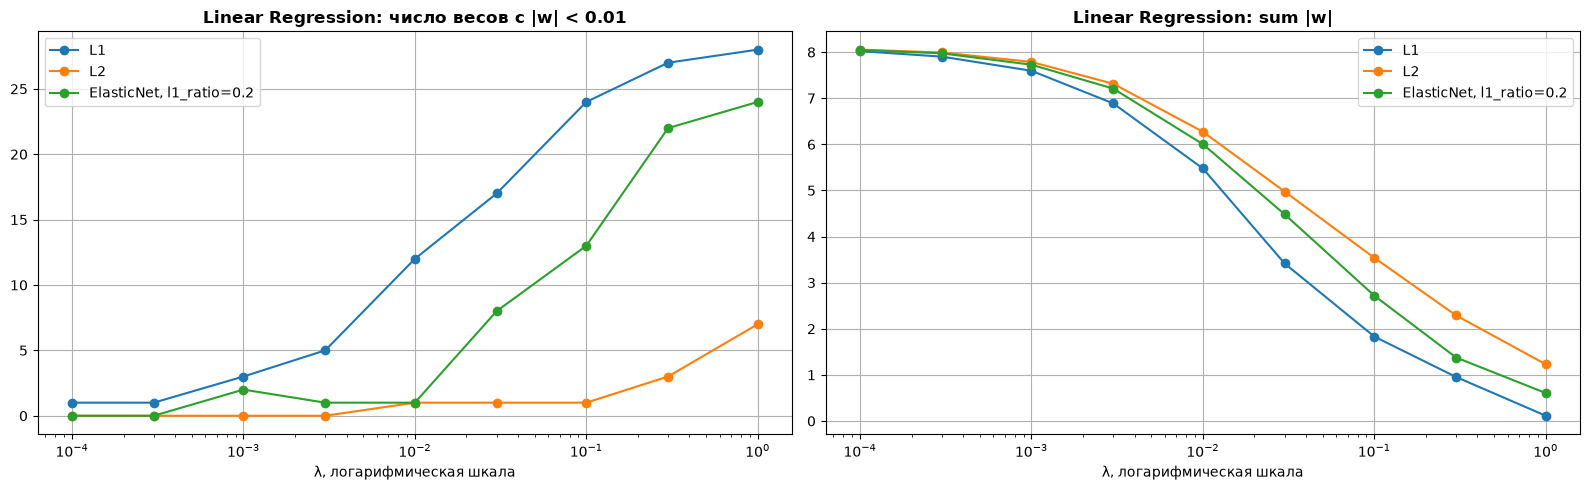

L1               L2            ElasticNet, l1_ratio=0.2           
       w = 0   RMSE val w = 0   RMSE val                    w = 0   RMSE val
λ                                                                           
0.0001     0   737.5290     0   737.4140                        0   737.4361
0.0003     1   736.1356     0   735.9062                        0   735.9686
0.0010     1   731.8903     0   731.2625                        0   731.4057
0.0030     5   722.9579     0   722.1473                        1   722.0000
0.0100    12   721.6579     0   713.1964                        1   712.6447
0.0300    17   760.2946     0   728.6289                        6   726.6587
0.1000    24   925.1844     0   814.2003                       12   835.6504
0.3000    26  1218.1230     0  1010.0958                       20  1079.0908
1.0000    28  1770.0013     0  1298.0199                       24  1419.2415

In [20]:
def plot_sparsity(res, best, metric, title):
    table = {}
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for reg, r in [('l1', None), ('l2', None), ('elasticnet', best.loc['elasticnet', 'l1_ratio'])]:
        part = res[res['reg'] == reg]
        if r is not None:
            part = part[part['l1_ratio'] == r]
        w = [m.w.detach() for m in part['model']]
        label = LABELS[reg] if r is None else f'ElasticNet, l1_ratio={r}'
        axes[0].plot(part['lam'], [(wi.abs() < EPS).sum().item() for wi in w], marker='o', label=label)
        axes[1].plot(part['lam'], [wi.abs().sum().item() for wi in w], marker='o', label=label)
        table[(label, 'w = 0')] = [(wi == 0).sum().item() for wi in w]
        table[(label, f'{metric} val')] = part['val_score'].values
    axes[0].set_title(f'{title}: число весов с |w| < {EPS}')
    axes[1].set_title(f'{title}: sum |w|')
    for ax in axes:
        ax.set_xscale('log')
        ax.set_xlabel('λ, логарифмическая шкала')
        ax.legend()
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(table, index=pd.Index(LAMBDAS, name='λ'))


plot_sparsity(res_a, best_a, 'RMSE', 'Linear Regression').round(4)

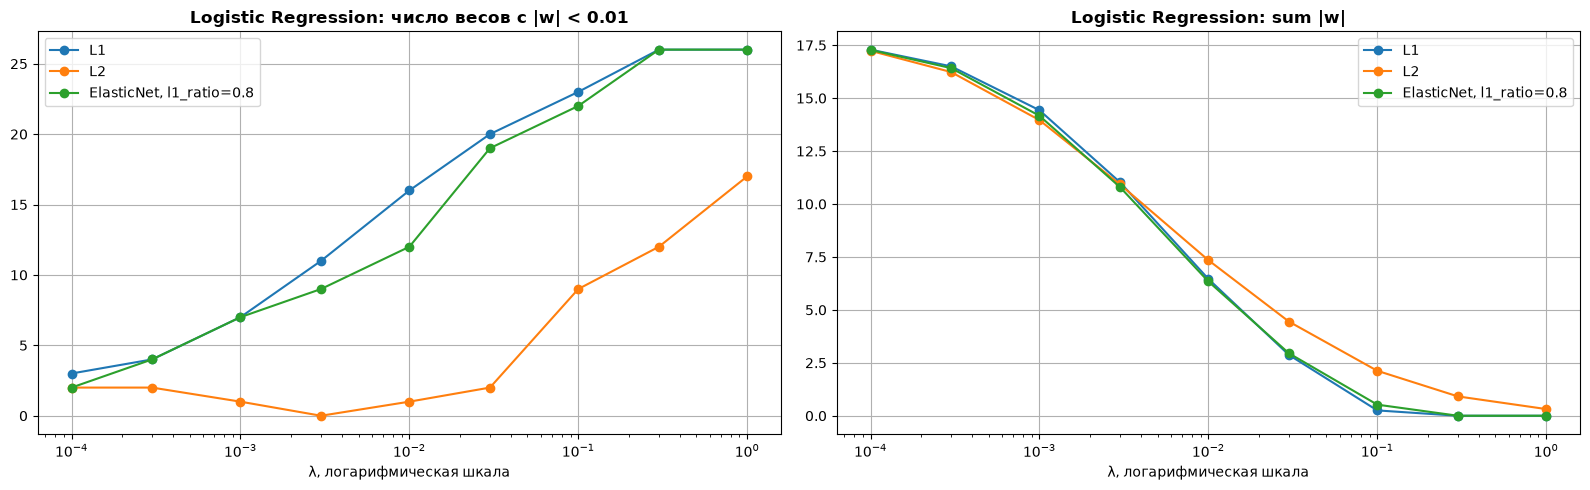

L1                L2             ElasticNet, l1_ratio=0.8            
       w = 0 LogLoss val w = 0 LogLoss val                    w = 0 LogLoss val
λ                                                                              
0.0001     2      0.4525     0      0.4524                        2      0.4525
0.0003     3      0.4518     0      0.4517                        3      0.4517
0.0010     7      0.4502     0      0.4517                        7      0.4504
0.0030    11      0.4514     0      0.4566                        9      0.4524
0.0100    16      0.4735     0      0.4767                       12      0.4748
0.0300    19      0.5335     0      0.5167                       19      0.5309
0.1000    22      0.6669     0      0.5797                       22      0.6424
0.3000    26      0.6937     0      0.6330                       26      0.6937
1.0000    26      0.6937     0      0.6695                       26      0.6937

In [21]:
plot_sparsity(res_ab, best_ab, 'LogLoss', 'Logistic Regression').round(4)

## 9. Вывод по части A

Я добавил в обе модели из лабораторной №1 четыре варианта регуляризации и подобрал λ по validation на сетке из `9` значений, для ElasticNet ещё по `3` значениям `l1_ratio`.

| Модель | Вариант | λ | Метрика на test | Точных нулей | Весов с $\lvert w \rvert < 0.01$ |
|---|---|---|---|---|---|
| Linear Regression | без регуляризации | `0` | RMSE `870.1`, R² `0.8063` | `0` из `29` | `0` |
| Linear Regression | L1 | `0.01` | RMSE `854.0`, R² `0.8134` | `12` из `29` | `12` |
| Linear Regression | L2 | `0.01` | RMSE `853.8`, R² `0.8135` | `0` из `29` | `1` |
| Linear Regression | ElasticNet, `l1_ratio=0.2` | `0.01` | RMSE `854.0`, R² `0.8134` | `1` из `29` | `1` |
| Logistic Regression | без регуляризации | `0` | LogLoss `0.4550`, F1 `0.7836` | `0` из `26` | `0` |
| Logistic Regression | L1 | `0.001` | LogLoss `0.4515`, F1 `0.7884` | `7` из `26` | `7` |
| Logistic Regression | L2 | `0.001` | LogLoss `0.4512`, F1 `0.7867` | `0` из `26` | `1` |
| Logistic Regression | ElasticNet, `l1_ratio=0.8` | `0.001` | LogLoss `0.4511`, F1 `0.7877` | `7` из `26` | `7` |

Качество:

- Регуляризация немного улучшила обе модели. У линейной регрессии RMSE на validation снизился с `738.2` до `712.6`, на test с `870.1` до `853.8`. У логистической LogLoss на test снизился с `0.4550` до `0.4511`, Accuracy выросла с `0.7808` до `0.7860`.
- Выигрыш получен за счёт меньшего переобучения. У линейной регрессии RMSE на train вырос с `737.5` до `757.5`, а на validation и test снизился: модель меньше подстраивается под train. Признаков `29` на `439` объектов train, для такой выборки это много.
- Эффект небольшой, около `2%` по RMSE на test и `0.004` по LogLoss, и почти одинаковый у L1, L2 и ElasticNet. Лучшие λ: `0.01` для линейной и `0.001` для логистической регрессии во всех вариантах.

Веса:

- L1 при лучшем λ обнулил `12` из `29` весов линейной регрессии: `holiday`, `mnth_2`, `mnth_3`, `mnth_4`, `mnth_6`, `mnth_8`, `mnth_11`, `mnth_12`, `weekday_2`...`weekday_5`. У логистической обнулены `7` из `26`: `Destination_Unknown`, `VIP_True`, `VIP_Unknown`, `Deck_F`, `Deck_T`, `Deck_Unknown`, `Side_Unknown`. RMSE и LogLoss на test при этом такие же, как у L2.
- L2 не дал ни одного нулевого веса ни при одном λ из сетки, он только уменьшает сумму $\lvert w \rvert$: с `8.09` до `6.27` у линейной и с `17.85` до `13.96` у логистической регрессии.
- Градиент L1 по ненулевому весу равен $\pm\lambda$ при любом размере веса и дотягивает малые веса до нуля. Градиент L2 $2 \lambda w$ уменьшается вместе с весом, поэтому вес приближается к нулю, но не становится нулём.
- ElasticNet у линейной регрессии выбрал `l1_ratio=0.2`, нижнюю границу сетки, и ведёт себя как L2: `1` нулевой вес. У логистической он выбрал `0.8` и обнулил те же `7` весов, что L1.
- Среди обнулённых L1 признаков `holiday`: в этих данных `holiday = weekday_1 + ... + weekday_5 - workingday`, столбец не добавляет информации к остальным.

Большой λ:

- При большом λ модели недообучаются. При λ=`0.3` и `1` L1 обнуляет все `26` весов логистической регрессии, LogLoss на validation `0.6937` почти равен LogLoss константного прогноза, около `0.693`.
- У линейной регрессии RMSE на validation при λ=`1` растёт с `738` до `1770` для L1 и до `1298` для L2.

Для линейной регрессии я бы выбрал L1 с λ=`0.01`: качество на test то же, что у L2, а `12` признаков можно не использовать. Для логистической регрессии по той же причине L1 с λ=`0.001`, без `7` признаков.

# Часть B. KNN Classification

Датасет **Dry Bean** содержит признаки формы зёрен фасоли, посчитанные по фотографиям. Задача - многоклассовая классификация сорта `Class`, всего `7` сортов.

| Признак | Описание |
|---|---|
| `Area`, `Perimeter`, `ConvexArea` | площадь, периметр и площадь выпуклой оболочки зерна в пикселях |
| `MajorAxisLength`, `MinorAxisLength` | длина большой и малой оси |
| `AspectRation`, `Eccentricity` | отношение осей и эксцентриситет эллипса |
| `EquivDiameter` | диаметр круга той же площади |
| `Extent`, `Solidity` | доля площади зерна в ограничивающем прямоугольнике и в выпуклой оболочке |
| `roundness`, `Compactness` | округлость и компактность |
| `ShapeFactor1` ... `ShapeFactor4` | коэффициенты формы |
| `Class` | сорт: `BARBUNYA`, `BOMBAY`, `CALI`, `DERMASON`, `HOROZ`, `SEKER`, `SIRA`. Целевая переменная |

## 1. Загрузка и краткое исследование

In [22]:
df_b = pd.read_excel('data_part_B/Dry_Bean_Dataset.xlsx')
print(f'Строк: {df_b.shape[0]}, столбцов: {df_b.shape[1]}')
df_b.head()

Строк: 13611, столбцов: 17


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [23]:
df_b.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [24]:
print(f'Пропусков всего: {df_b.isna().sum().sum()}')
print(f'Дубликатов строк: {df_b.duplicated().sum()} из {len(df_b)}')

Пропусков всего: 0
Дубликатов строк: 68 из 13611


In [25]:
df_b.describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
Area,53048.284549,29324.095717,20420.000000,254616.000000
Perimeter,855.283459,214.289696,524.736000,1985.370000
MajorAxisLength,320.141867,85.694186,183.601165,738.860153
MinorAxisLength,202.270714,44.970091,122.512653,460.198497
AspectRation,1.583242,0.246678,1.024868,2.430306
Eccentricity,0.750895,0.092002,0.218951,0.911423
ConvexArea,53768.200206,29774.915817,20684.000000,263261.000000
EquivDiameter,253.064220,59.177120,161.243764,569.374358
Extent,0.749733,0.049086,0.555315,0.866195
Solidity,0.987143,0.004660,0.919246,0.994677


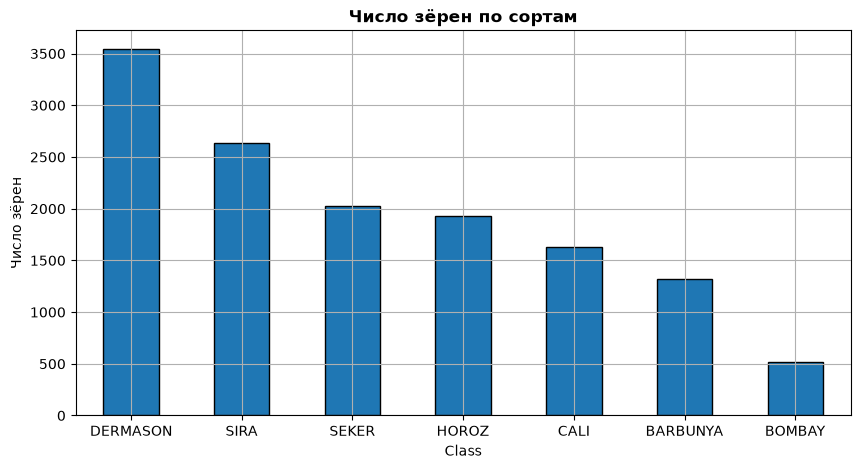

,доля
Class,
DERMASON,0.261
SIRA,0.194
SEKER,0.149
HOROZ,0.142
CALI,0.120
BARBUNYA,0.097
BOMBAY,0.038


In [26]:
counts_b = df_b['Class'].value_counts()
counts_b.plot.bar(rot=0, edgecolor='black')
plt.title('Число зёрен по сортам')
plt.ylabel('Число зёрен')
plt.show()
(counts_b / len(df_b)).round(3).rename('доля').to_frame()

In [27]:
print('Площадь зерна по сортам:')
df_b.groupby('Class')['Area'].agg(['mean', 'min', 'max']).round(0).astype(int)

Площадь зерна по сортам:


,mean,min,max
Class,,,
BARBUNYA,69804,41487,115967
BOMBAY,173485,114004,254616
CALI,75538,45504,116272
DERMASON,32119,20420,42159
HOROZ,53649,33006,81929
SEKER,39881,28395,61150
SIRA,44729,31519,63612


В датасете `13611` зёрен и `16` числовых признаков, пропусков нет, `68` строк-дубликатов. Классы несбалансированы: от `26.1%` у `DERMASON` до `3.8%` у `BOMBAY`, поэтому кроме Accuracy я смотрю Macro F1. Сорта различаются по размеру: средняя площадь `BOMBAY` не меньше чем в `2.3` раза больше, чем у любого другого сорта. Масштабы признаков различаются сильно: `Area` до `254616`, `ShapeFactor2` около `0.0017`. Без стандартизации расстояние между зёрнами будут определять `Area` и `ConvexArea`.

## 2. Формирование X и y

Дубликаты удаляются до split, чтобы одно и то же зерно не попало одновременно в train и test. Сорта кодируются числами `0`...`6` в алфавитном порядке.

In [28]:
df_b = df_b.drop_duplicates().reset_index(drop=True)
CLASSES = sorted(df_b['Class'].unique())

y_b = df_b['Class'].map({c: i for i, c in enumerate(CLASSES)})
X_b = df_b.drop(columns='Class')
feature_names_b = X_b.columns.tolist()
print(f'Кодировка сортов: {dict(enumerate(CLASSES))}')
print(f'Размер X: {tuple(X_b.shape)}, размер y: {tuple(y_b.shape)}')

Кодировка сортов: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
Размер X: (13543, 16), размер y: (13543,)


## 3. Train/validation/test split

In [29]:
X_train_b, X_val_b, X_test_b, y_train_b, y_val_b, y_test_b = train_val_test_split(
    torch.tensor(X_b.values, dtype=DTYPE), torch.tensor(y_b.values, dtype=torch.long))
print(f'Количество объектов: train {X_train_b.shape[0]}, validation {X_val_b.shape[0]}, test {X_test_b.shape[0]}')
print('Доли сортов в выборках:')

pd.DataFrame({
    name: pd.Series(y.numpy()).map(dict(enumerate(CLASSES))).value_counts(normalize=True)
    for name, y in [('train', y_train_b), ('val', y_val_b), ('test', y_test_b)]
}).round(3)

Количество объектов: train 8127, validation 2708, test 2708
Доли сортов в выборках:


,train,val,test
DERMASON,0.264,0.264,0.254
SIRA,0.192,0.195,0.202
SEKER,0.149,0.144,0.157
HOROZ,0.139,0.141,0.129
CALI,0.122,0.125,0.112
BARBUNYA,0.097,0.095,0.103
BOMBAY,0.039,0.035,0.042


## 4. Preprocessing

Пропусков и категориальных признаков нет. Признаки различаются по масштабу на восемь порядков, поэтому все столбцы стандартизируются по train. Нестандартизированные копии остаются для сравнения в пункте 12.

In [30]:
all_idx_b = list(range(X_train_b.shape[1]))
X_train_b_s, X_val_b_s, X_test_b_s = standardize(X_train_b, X_val_b, X_test_b, all_idx_b)
print(f'Наибольшее по модулю среднее признака train после стандартизации: {X_train_b_s.mean(dim=0).abs().max():.2e}')
print(f'Стандартное отклонение признаков train после стандартизации: от {X_train_b_s.std(dim=0).min():.4f} до {X_train_b_s.std(dim=0).max():.4f}')

Наибольшее по модулю среднее признака train после стандартизации: 5.36e-06
Стандартное отклонение признаков train после стандартизации: от 1.0000 до 1.0000


## 5-8. Класс KNN

| Метод | Что делает |
|---|---|
| `__init__` | сохраняет параметры `k`, `task` (`classification` или `regression`) и `distance` (`euclidean` или `manhattan`) |
| `fit` | запоминает обучающую выборку, обучения как такового нет |
| `_distances` | расстояния от батча объектов до всех объектов train |
| `kneighbors` | индексы `k` ближайших соседей |
| `predict` | для классификации голосование большинством, для регрессии среднее целевой переменной соседей |

Формулы расстояний между объектами $x$ и $z$:

- Euclidean: $d(x, z) = \sqrt{\sum_j (x_j - z_j)^2}$.
- Manhattan: $d(x, z) = \sum_j \lvert x_j - z_j \rvert$.

Расстояния считаются батчами по `256` объектов, чтобы матрица разностей размером `батч × n_train × число признаков` помещалась в память. При равенстве голосов `argmax` выбирает класс с меньшим номером, при равных расстояниях `torch.topk` берёт любого из соседей.

`fit` только сохраняет ссылки на данные, поэтому выполняется мгновенно. `predict` считает расстояние от каждого объекта до каждого объекта train, сложность $O(n_{test} \cdot n_{train} \cdot d)$, где $d$ - число признаков. Поэтому обучение у KNN быстрое, а прогноз медленный.

In [31]:
class KNN:
    def __init__(self, k=5, task='classification', distance='euclidean', batch_size=256):
        if task not in ('classification', 'regression'):
            raise ValueError(f'Неизвестный task: {task}')
        if distance not in ('euclidean', 'manhattan'):
            raise ValueError(f'Неизвестное расстояние: {distance}')
        self.k = k
        self.task = task
        self.distance = distance
        self.batch_size = batch_size

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        if self.task == 'classification':
            self.n_classes = int(y.max().item()) + 1
        return self

    def _distances(self, X):
        diff = X[:, None, :] - self.X_train[None, :, :] # (batch, n_train, n_features)
        if self.distance == 'euclidean':
            return torch.sqrt((diff ** 2).sum(dim=2))
        return diff.abs().sum(dim=2)

    def kneighbors(self, X):
        idx = []
        for start in range(0, X.shape[0], self.batch_size):
            d = self._distances(X[start:start + self.batch_size])
            idx.append(torch.topk(d, self.k, dim=1, largest=False).indices) # k наименьших расстояний
        return torch.cat(idx)

    def predict(self, X):
        neighbors_y = self.y_train[self.kneighbors(X)] # (n, k) целевая переменная соседей
        if self.task == 'classification':
            votes = torch.zeros(X.shape[0], self.n_classes)
            votes.scatter_add_(1, neighbors_y, torch.ones(neighbors_y.shape)) # число голосов за каждый класс
            return votes.argmax(dim=1)
        return neighbors_y.float().mean(dim=1)

Проверка на маленьком примере: две точки класса `0` около начала координат и три точки класса `1` около `(5, 5)`.

In [32]:
X_toy = torch.tensor([[0., 0.], [1., 0.], [5., 5.], [6., 5.], [5., 6.]])
y_toy = torch.tensor([0, 0, 1, 1, 1])
q = torch.tensor([[0.5, 0.5], [4., 4.]])
for distance in ['euclidean', 'manhattan']:
    knn = KNN(k=3, distance=distance).fit(X_toy, y_toy)
    print(f'{distance}, расстояния от (0.5, 0.5) до обучающих точек: {knn._distances(q)[0].numpy().round(3)}')
    print(f'{distance}, индексы 3 ближайших соседей: {knn.kneighbors(q).tolist()}, прогноз класса: {knn.predict(q).tolist()}')
print(f'regression, k=2, целевая переменная 0 и 10: прогноз {KNN(k=2, task="regression").fit(X_toy, y_toy.float() * 10).predict(q).tolist()}')

euclidean, расстояния от (0.5, 0.5) до обучающих точек: [0.707 0.707 6.364 7.106 7.106]
euclidean, индексы 3 ближайших соседей: [[0, 1, 2], [2, 3, 4]], прогноз класса: [0, 1]
manhattan, расстояния от (0.5, 0.5) до обучающих точек: [ 1.  1.  9. 10. 10.]
manhattan, индексы 3 ближайших соседей: [[0, 1, 2], [2, 3, 4]], прогноз класса: [0, 1]
regression, k=2, целевая переменная 0 и 10: прогноз [0.0, 10.0]


## 9-11. Подбор k по validation, сравнение Euclidean и Manhattan

Значения `k`: `1`, `3`, `5`, `7`, `9`, `11`, `15`, `21`, `31`, `51`, `75`, `101`. Нечётные `k` уменьшают число равенств голосов. Классы несбалансированы, поэтому `k` выбирается по Macro F1 на validation.

In [33]:
K_VALUES = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 75, 101]
DISTANCES = ['euclidean', 'manhattan']


def knn_grid(task, data, y_tr, y_val, score_fn):
    rows = []
    for scaling, (X_tr, X_val) in data.items():
        for distance in DISTANCES:
            for k in K_VALUES:
                y_pred = KNN(k=k, task=task, distance=distance).fit(X_tr, y_tr).predict(X_val)
                rows.append({'scaling': scaling, 'distance': distance, 'k': k, **score_fn(y_val, y_pred)})
    return pd.DataFrame(rows)


def cls_scores(y_true, y_pred):
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Macro F1': f1_score(y_true, y_pred, average='macro')}


grid_b = knn_grid('classification', {'со scaling': (X_train_b_s, X_val_b_s), 'без scaling': (X_train_b, X_val_b)},
                  y_train_b, y_val_b, cls_scores)
print('Метрики на validation, со scaling:')
grid_b[grid_b['scaling'] == 'со scaling'].pivot(index='k', columns='distance', values=['Accuracy', 'Macro F1']).round(4)

Метрики на validation, со scaling:


Accuracy            Macro F1          
distance euclidean manhattan euclidean manhattan
k                                               
1           0.8999    0.8977    0.9172    0.9150
3           0.9232    0.9180    0.9357    0.9311
5           0.9243    0.9247    0.9384    0.9375
7           0.9243    0.9228    0.9383    0.9358
9           0.9276    0.9254    0.9425    0.9377
11          0.9261    0.9236    0.9406    0.9358
15          0.9232    0.9210    0.9377    0.9340
21          0.9228    0.9217    0.9364    0.9345
31          0.9239    0.9221    0.9370    0.9337
51          0.9228    0.9217    0.9357    0.9327
75          0.9188    0.9210    0.9316    0.9319
101         0.9140    0.9151    0.9269    0.9253

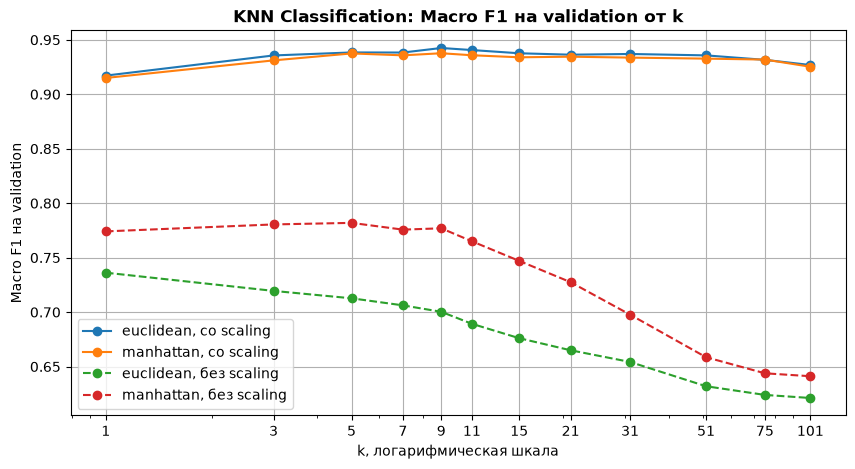

In [34]:
def plot_k(grid, metric, title):
    for (scaling, distance), part in grid.groupby(['scaling', 'distance'], sort=False):
        plt.plot(part['k'], part[metric], marker='o', linestyle='-' if scaling == 'со scaling' else '--',
                 label=f'{distance}, {scaling}')
    plt.xscale('log')
    plt.xticks(K_VALUES, K_VALUES)
    plt.title(title)
    plt.xlabel('k, логарифмическая шкала')
    plt.ylabel(f'{metric} на validation')
    plt.legend()
    plt.show()


plot_k(grid_b, 'Macro F1', 'KNN Classification: Macro F1 на validation от k')

## 12. Без scaling и со scaling

Для каждой комбинации scaling и расстояния выбран лучший `k` по Macro F1 на validation.

In [35]:
best_b = grid_b.loc[grid_b.groupby(['scaling', 'distance'], sort=False)['Macro F1'].idxmax()].reset_index(drop=True)
print('Лучший k каждой комбинации, метрики на validation:')
best_b.set_index(['scaling', 'distance']).round(4)

Лучший k каждой комбинации, метрики на validation:


k  Accuracy  Macro F1
scaling     distance                        
со scaling  euclidean  9    0.9276    0.9425
            manhattan  9    0.9254    0.9377
без scaling euclidean  1    0.7308    0.7362
            manhattan  5    0.7799    0.7819

In [36]:
print('Macro F1 на validation, без scaling:')
grid_b[grid_b['scaling'] == 'без scaling'].pivot(index='k', columns='distance', values='Macro F1').round(4)

Macro F1 на validation, без scaling:


distance,euclidean,manhattan
k,,
1,0.7362,0.7741
3,0.7195,0.7805
5,0.7127,0.7819
7,0.7062,0.7757
9,0.7003,0.7770
11,0.6893,0.7650
15,0.6760,0.7470
21,0.6650,0.7275
31,0.6542,0.6977


## 13. Итоговая оценка на test

Конфигурация с лучшим Macro F1 на validation обучается на train и один раз проверяется на test. Для сравнения в таблице те же метрики для лучших `k` остальных комбинаций.

In [37]:
data_b = {'со scaling': (X_train_b_s, X_test_b_s), 'без scaling': (X_train_b, X_test_b)}
preds_b = {}
rows_b = []
for _, r in best_b.iterrows():
    X_tr, X_te = data_b[r['scaling']]
    y_pred = KNN(k=int(r['k']), distance=r['distance']).fit(X_tr, y_train_b).predict(X_te)
    preds_b[(r['scaling'], r['distance'])] = y_pred
    rows_b.append({'scaling': r['scaling'], 'distance': r['distance'], 'k': int(r['k']),
                   'Macro F1 val': r['Macro F1'], **{f'{m} test': v for m, v in cls_scores(y_test_b, y_pred).items()}})
test_b = pd.DataFrame(rows_b).set_index(['scaling', 'distance'])
test_b.round(4)

k  Macro F1 val  Accuracy test  Macro F1 test
scaling     distance                                                
со scaling  euclidean  9        0.9425         0.9173         0.9297
            manhattan  9        0.9377         0.9162         0.9288
без scaling euclidean  1        0.7362         0.7190         0.7225
            manhattan  5        0.7819         0.7725         0.7759

In [38]:
final_b = best_b.loc[best_b['Macro F1'].idxmax()]
y_pred_test_b = preds_b[(final_b['scaling'], final_b['distance'])]
print(f'Итоговая модель: k={int(final_b["k"])}, distance={final_b["distance"]}, {final_b["scaling"]}')
print(f'Accuracy на test: {accuracy_score(y_test_b, y_pred_test_b):.4f}')
print(f'Macro F1 на test: {f1_score(y_test_b, y_pred_test_b, average="macro"):.4f}')

Итоговая модель: k=9, distance=euclidean, со scaling
Accuracy на test: 0.9173
Macro F1 на test: 0.9297


## 14. Confusion matrix

Строка - истинный сорт, столбец - предсказанный. На диагонали верные ответы, вне диагонали видно, какие сорта модель путает между собой.

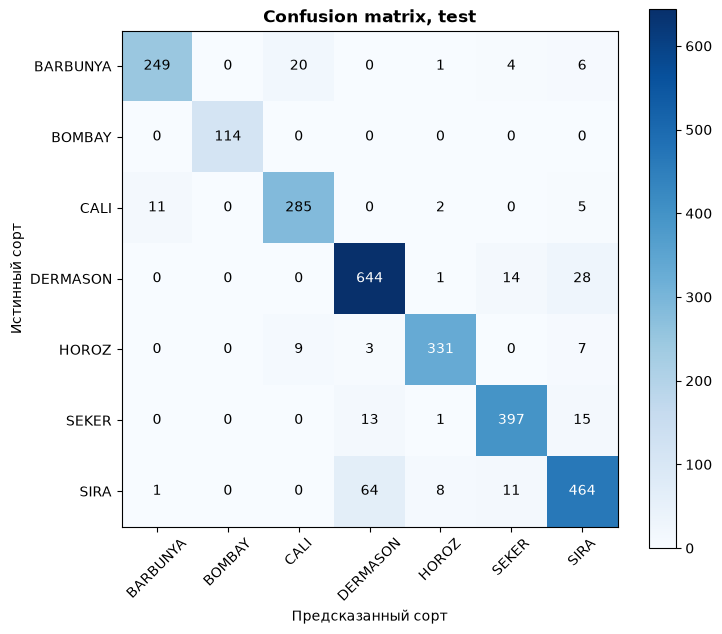

,Recall,Precision,F1
BARBUNYA,0.8893,0.9540,0.9205
BOMBAY,1.0000,1.0000,1.0000
CALI,0.9406,0.9076,0.9238
DERMASON,0.9374,0.8895,0.9128
HOROZ,0.9457,0.9622,0.9539
SEKER,0.9319,0.9319,0.9319
SIRA,0.8467,0.8838,0.8649


In [39]:
cm_b = confusion_matrix(y_test_b, y_pred_test_b)
plt.figure(figsize=(8, 7))
plt.imshow(cm_b, cmap='Blues')
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        plt.text(j, i, cm_b[i, j], ha='center', va='center', color='white' if cm_b[i, j] > cm_b.max() / 2 else 'black')
plt.xticks(range(len(CLASSES)), CLASSES, rotation=45)
plt.yticks(range(len(CLASSES)), CLASSES)
plt.xlabel('Предсказанный сорт')
plt.ylabel('Истинный сорт')
plt.title('Confusion matrix, test')
plt.grid(False)
plt.colorbar()
plt.show()

pd.DataFrame({
    'Recall': cm_b.diagonal() / cm_b.sum(axis=1),
    'Precision': cm_b.diagonal() / cm_b.sum(axis=0),
    'F1': f1_score(y_test_b, y_pred_test_b, average=None),
}, index=CLASSES).round(4)

## 15. Вывод по части B

Я реализовал класс `KNN` с параметрами `k`, `task`, `distance`, проверил `12` значений `k` для Euclidean и Manhattan со scaling и без него и выбрал конфигурацию по Macro F1 на validation.

| Конфигурация | k | Macro F1 val | Accuracy test | Macro F1 test |
|---|---|---|---|---|
| Euclidean, со scaling | `9` | `0.9425` | `0.9173` | `0.9297` |
| Manhattan, со scaling | `9` | `0.9377` | `0.9162` | `0.9288` |
| Euclidean, без scaling | `1` | `0.7362` | `0.7190` | `0.7225` |
| Manhattan, без scaling | `5` | `0.7819` | `0.7725` | `0.7759` |

Итоговая модель: Euclidean, `k=9`, со scaling. На test Accuracy `0.9173`, Macro F1 `0.9297`.

Scaling:

- Scaling поднимает Macro F1 на test с `0.7225` до `0.9297` у Euclidean и с `0.7759` до `0.9288` у Manhattan.
- Без стандартизации соседи выбираются почти только по `Area` и `ConvexArea` со стандартным отклонением около `29000`. Признаки формы со стандартным отклонением от `0.0006` до `0.25` в расстояние почти не попадают.
- Без scaling качество падает с ростом `k`: у Euclidean Macro F1 с `0.7362` при `k=1` до `0.6212` при `k=101`. Средние площади сортов `SEKER`, `SIRA` и `HOROZ` лежат между `39881` и `53649`, поэтому среди зёрен близкого размера много зёрен других сортов.

Расстояние и k:

- Со scaling Euclidean и Manhattan почти не различаются: `0.9425` и `0.9377` на validation, `0.9297` и `0.9288` на test.
- Без scaling Manhattan лучше на `0.046`. Euclidean возводит разности в квадрат, поэтому доля крупного признака в расстоянии у него больше, чем у Manhattan.
- Со scaling при `k=1` Macro F1 `0.9172`, модель повторяет шум отдельных зёрен. Максимум при `k=9`, дальше качество снижается до `0.9269` при `k=101`, границы классов размываются.

Ошибки по confusion matrix:

- `BOMBAY` распознан без ошибок, `114` из `114`. Это самые крупные зёрна: средняя площадь `173485`, у остальных сортов от `32119` до `75538`.
- Больше всего ошибок между `SIRA` и `DERMASON`: `64` зерна `SIRA` предсказаны как `DERMASON`, `28` наоборот. У `SIRA` самый низкий F1 `0.8649`. По площади эту пару не объяснить, средние `44729` и `32119`, причину я не проверял.
- Вторая пара - `BARBUNYA` и `CALI`, `20` и `11` ошибок. Их средние площади `69804` и `75538` ближе, чем у любой другой пары сортов.

# Часть C. KNN Regression

Датасет **Seoul Bike Sharing Demand** содержит почасовое число арендованных велосипедов в Сеуле за год с декабря 2017 по ноябрь 2018 и погоду в этот час. Задача - регрессия, целевая переменная `Rented Bike Count`.

| Признак | Описание |
|---|---|
| `Date`, `Hour` | дата и час |
| `Temperature`, `Dew point temperature` | температура воздуха и точки росы, °C |
| `Humidity`, `Wind speed`, `Visibility` | влажность в %, скорость ветра в м/с, видимость в десятках метров |
| `Solar Radiation`, `Rainfall`, `Snowfall` | солнечная радиация в МДж/м², осадки в мм, снег в см |
| `Seasons`, `Holiday` | сезон и праздничный день |
| `Functioning Day` | работал ли прокат в этот день |
| `Rented Bike Count` | число арендованных велосипедов за час. Целевая переменная |

Имена столбцов в файле содержат единицы измерения и символ `°`, поэтому при загрузке я переименовываю их в короткие, целевая переменная `Rented Bike Count` дальше называется `Count`.

## 1. Загрузка и краткое исследование

In [40]:
df_c = pd.read_csv('data_part_C/SeoulBikeData.csv', encoding='cp1252')
df_c.columns = ['Date', 'Count', 'Hour', 'Temperature', 'Humidity', 'WindSpeed', 'Visibility', 'DewPoint',
                'SolarRadiation', 'Rainfall', 'Snowfall', 'Seasons', 'Holiday', 'FunctioningDay']
print(f'Строк: {df_c.shape[0]}, столбцов: {df_c.shape[1]}')
df_c.head()

Строк: 8760, столбцов: 14


,Date,Count,Hour,Temperature,Humidity,WindSpeed,Visibility,DewPoint,SolarRadiation,Rainfall,Snowfall,Seasons,Holiday,FunctioningDay
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [41]:
df_c.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            8760 non-null   object 
 1   Count           8760 non-null   int64  
 2   Hour            8760 non-null   int64  
 3   Temperature     8760 non-null   float64
 4   Humidity        8760 non-null   int64  
 5   WindSpeed       8760 non-null   float64
 6   Visibility      8760 non-null   int64  
 7   DewPoint        8760 non-null   float64
 8   SolarRadiation  8760 non-null   float64
 9   Rainfall        8760 non-null   float64
 10  Snowfall        8760 non-null   float64
 11  Seasons         8760 non-null   object 
 12  Holiday         8760 non-null   object 
 13  FunctioningDay  8760 non-null   object 
dtypes: float64(6), int64(4), object(4)
memory usage: 958.3+ KB


In [42]:
print(f'Пропусков всего: {df_c.isna().sum().sum()}')
print(f'Дубликатов строк: {df_c.duplicated().sum()}')
df_c[['Count']].describe().T.round(1)

Пропусков всего: 0
Дубликатов строк: 0


,count,mean,std,min,25%,50%,75%,max
Count,8760.0,704.6,645.0,0.0,191.0,504.5,1065.2,3556.0


In [43]:
counts_fd = df_c['FunctioningDay'].value_counts()
print(f'Часов, когда прокат работал: {counts_fd["Yes"]}, не работал: {counts_fd["No"]}')
print(f'Count в часы, когда прокат не работал: от {df_c.loc[df_c.FunctioningDay == "No", "Count"].min()} до {df_c.loc[df_c.FunctioningDay == "No", "Count"].max()}')

Часов, когда прокат работал: 8465, не работал: 295
Count в часы, когда прокат не работал: от 0 до 0


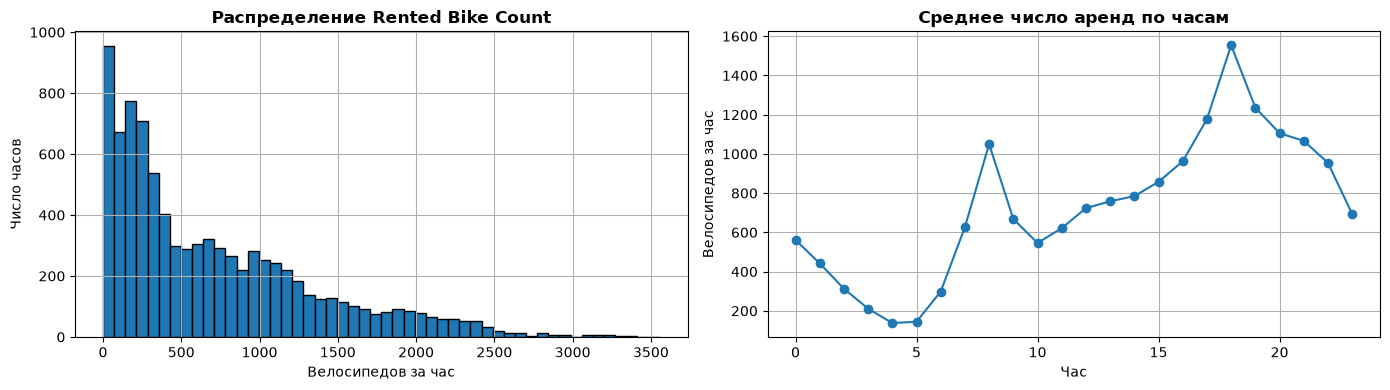

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df_c['Count'], bins=50, edgecolor='black')
axes[0].set_title('Распределение Rented Bike Count')
axes[0].set_xlabel('Велосипедов за час')
axes[0].set_ylabel('Число часов')

df_c[df_c['FunctioningDay'] == 'Yes'].groupby('Hour')['Count'].mean().plot(ax=axes[1], marker='o')
axes[1].set_title('Среднее число аренд по часам')
axes[1].set_xlabel('Час')
axes[1].set_ylabel('Велосипедов за час')
plt.tight_layout()
plt.show()

В датасете `8760` часов, пропусков и дубликатов нет. В `295` часов прокат не работал, и `Count` в них равен `0`. Распределение `Count` скошено вправо: медиана `504.5`, среднее `704.6`, максимум `3556`. По часам видны два пика спроса: утром в `8` часов и вечером в `18`, ночью спрос минимален.

## 2. Формирование X и y

- Строки с `FunctioningDay = No` удаляются, в эти часы прокат не работал и спрос не измерялся.
- Из `Date` берётся признак выходного дня `Weekend`, сама дата удаляется.
- `Hour` заменяется на `HourSin` и `HourCos`. Иначе для KNN `23` и `0` часов оказались бы на расстоянии `23`, хотя это соседние часы.
- `Seasons` кодируется one-hot, `Holiday` переводится в `0`/`1`.

In [45]:
df_c = df_c[df_c['FunctioningDay'] == 'Yes'].reset_index(drop=True)

y_c = df_c['Count'].astype(float)
X_c = df_c.drop(columns=['Count', 'FunctioningDay'])
X_c['Weekend'] = (pd.to_datetime(X_c['Date'], format='%d/%m/%Y').dt.weekday >= 5).astype(float)
X_c['HourSin'] = np.sin(2 * np.pi * X_c['Hour'] / 24)
X_c['HourCos'] = np.cos(2 * np.pi * X_c['Hour'] / 24)
X_c['Holiday'] = (X_c['Holiday'] == 'Holiday').astype(float)
X_c = X_c.drop(columns=['Date', 'Hour'])
X_c = pd.get_dummies(X_c, columns=['Seasons'], drop_first=True, dtype=float)
feature_names_c = X_c.columns.tolist()
print(f'Признаки: {feature_names_c}')
print(f'Размер X: {tuple(X_c.shape)}, размер y: {tuple(y_c.shape)}')

Признаки: ['Temperature', 'Humidity', 'WindSpeed', 'Visibility', 'DewPoint', 'SolarRadiation', 'Rainfall', 'Snowfall', 'Holiday', 'Weekend', 'HourSin', 'HourCos', 'Seasons_Spring', 'Seasons_Summer', 'Seasons_Winter']
Размер X: (8465, 15), размер y: (8465,)


## 3. Train/validation/test split

In [46]:
X_train_c, X_val_c, X_test_c, y_train_c, y_val_c, y_test_c = train_val_test_split(
    torch.tensor(X_c.values, dtype=DTYPE), torch.tensor(y_c.values, dtype=DTYPE))
print(f'Количество объектов: train {X_train_c.shape[0]}, validation {X_val_c.shape[0]}, test {X_test_c.shape[0]}')
print(f'Среднее Count: train {y_train_c.mean():.1f}, validation {y_val_c.mean():.1f}, test {y_test_c.mean():.1f}')

Количество объектов: train 5079, validation 1693, test 1693
Среднее Count: train 731.7, validation 728.7, test 722.1


## 4. Preprocessing

Пропусков нет. Все признаки стандартизируются по train, включая бинарные, чтобы каждый признак вносил в расстояние вклад одного масштаба. Без этого `Visibility` с разбросом в сотни единиц определял бы соседей почти в одиночку.

In [47]:
X_c.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
Temperature,12.77,12.10,-17.8,39.40
Humidity,58.15,20.48,0.0,98.00
WindSpeed,1.73,1.03,0.0,7.40
Visibility,1433.87,609.05,27.0,2000.00
DewPoint,3.94,13.24,-30.6,27.20
SolarRadiation,0.57,0.87,0.0,3.52
Rainfall,0.15,1.13,0.0,35.00
Snowfall,0.08,0.44,0.0,8.80
Holiday,0.05,0.21,0.0,1.00
Weekend,0.29,0.45,0.0,1.00


In [48]:
all_idx_c = list(range(X_train_c.shape[1]))
X_train_c_s, X_val_c_s, X_test_c_s = standardize(X_train_c, X_val_c, X_test_c, all_idx_c)
print(f'Стандартное отклонение признаков train после стандартизации: от {X_train_c_s.std(dim=0).min():.4f} до {X_train_c_s.std(dim=0).max():.4f}')

Стандартное отклонение признаков train после стандартизации: от 1.0000 до 1.0000


## 5-10. KNN в режиме regression, подбор k, Euclidean и Manhattan, scaling

Используется тот же класс `KNN` с `task='regression'`, прогноз - среднее `Count` по `k` ближайшим соседям. `k` выбирается по RMSE на validation.

In [49]:
grid_c = knn_grid('regression', {'со scaling': (X_train_c_s, X_val_c_s), 'без scaling': (X_train_c, X_val_c)},
                  y_train_c, y_val_c, evaluate_reg)
print('Метрики на validation, со scaling:')
grid_c[grid_c['scaling'] == 'со scaling'].pivot(index='k', columns='distance', values=['RMSE', 'R2']).round(4)

Метрики на validation, со scaling:


RMSE                  R2          
distance euclidean manhattan euclidean manhattan
k                                               
1         299.7336  280.0263    0.7749    0.8035
3         251.5896  234.6594    0.8414    0.8620
5         248.9305  231.8908    0.8447    0.8653
7         252.7715  239.8998    0.8399    0.8558
9         257.3206  241.6784    0.8341    0.8537
11        264.4088  242.6892    0.8248    0.8524
15        272.3587  249.3925    0.8141    0.8442
21        283.5937  260.0593    0.7985    0.8305
31        293.4560  270.0090    0.7842    0.8173
51        312.1281  288.3806    0.7559    0.7916
75        329.7378  304.6372    0.7276    0.7675
101       344.3927  318.4677    0.7028    0.7459

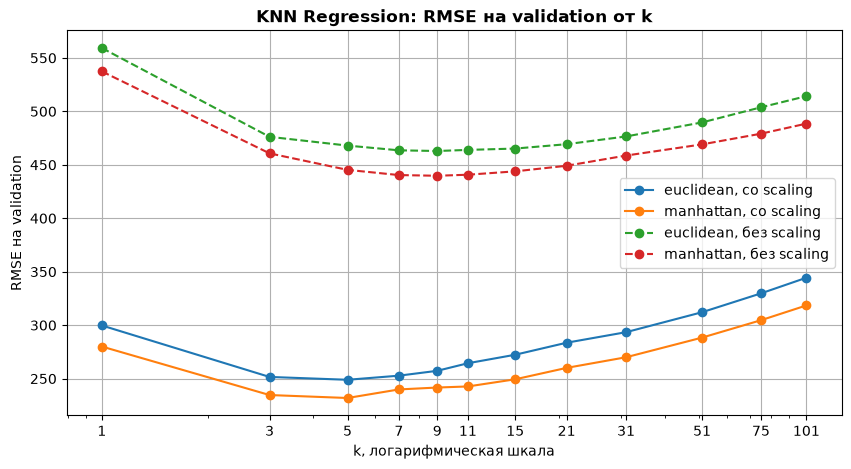

In [50]:
plot_k(grid_c, 'RMSE', 'KNN Regression: RMSE на validation от k')

In [51]:
best_c = grid_c.loc[grid_c.groupby(['scaling', 'distance'], sort=False)['RMSE'].idxmin()].reset_index(drop=True)
print('Лучший k каждой комбинации, метрики на validation:')
best_c.set_index(['scaling', 'distance']).round({'MAE': 1, 'RMSE': 1, 'R2': 4})

Лучший k каждой комбинации, метрики на validation:


k    MAE   RMSE      R2
scaling     distance                          
со scaling  euclidean  5  156.0  248.9  0.8447
            manhattan  5  144.7  231.9  0.8653
без scaling euclidean  9  331.9  462.9  0.4630
            manhattan  9  311.9  439.8  0.5154

## 11-12. Итоговая оценка и baseline

Основной baseline, как в лабораторной №1, предсказывает всем объектам одно число - среднее `Count` по train. Второй baseline сильнее: он предсказывает среднее `Count` по train для того же часа суток. Час берётся из той же перестановки split, что и `X`.

In [52]:
data_c = {'со scaling': (X_train_c_s, X_test_c_s), 'без scaling': (X_train_c, X_test_c)}
preds_c = {}
rows_c = {}
for _, r in best_c.iterrows():
    X_tr, X_te = data_c[r['scaling']]
    y_pred = KNN(k=int(r['k']), task='regression', distance=r['distance']).fit(X_tr, y_train_c).predict(X_te)
    preds_c[(r['scaling'], r['distance'])] = y_pred
    rows_c[f'KNN, {r["distance"]}, {r["scaling"]}, k={int(r["k"])}'] = evaluate_reg(y_test_c, y_pred)

hour_c = torch.tensor(df_c['Hour'].values)
hour_train_c, _, hour_test_c, _, _, _ = train_val_test_split(hour_c, hour_c) # та же перестановка, что у X
hour_mean_c = torch.stack([y_train_c[hour_train_c == h].mean() for h in range(24)])
rows_c['Baseline, среднее train'] = evaluate_reg(y_test_c, torch.full_like(y_test_c, y_train_c.mean().item()))
rows_c['Baseline, среднее train по часу'] = evaluate_reg(y_test_c, hour_mean_c[hour_test_c])

final_c = best_c.loc[best_c['RMSE'].idxmin()]
y_pred_test_c = preds_c[(final_c['scaling'], final_c['distance'])]
print(f'Итоговая модель: k={int(final_c["k"])}, distance={final_c["distance"]}, {final_c["scaling"]}')
print('Метрики на test, MAE и RMSE в велосипедах за час:')
test_c = pd.DataFrame(rows_c).T
test_c.round({'MAE': 1, 'RMSE': 1, 'R2': 4}) + 0.0

Итоговая модель: k=5, distance=manhattan, со scaling
Метрики на test, MAE и RMSE в велосипедах за час:


,MAE,RMSE,R2
"KNN, euclidean, со scaling, k=5",161.1,262.3,0.8434
"KNN, manhattan, со scaling, k=5",154.4,250.4,0.8574
"KNN, euclidean, без scaling, k=9",334.2,469.4,0.4987
"KNN, manhattan, без scaling, k=9",312.5,444.0,0.5515
"Baseline, среднее train",531.5,663.1,-0.0002
"Baseline, среднее train по часу",418.3,540.6,0.3352


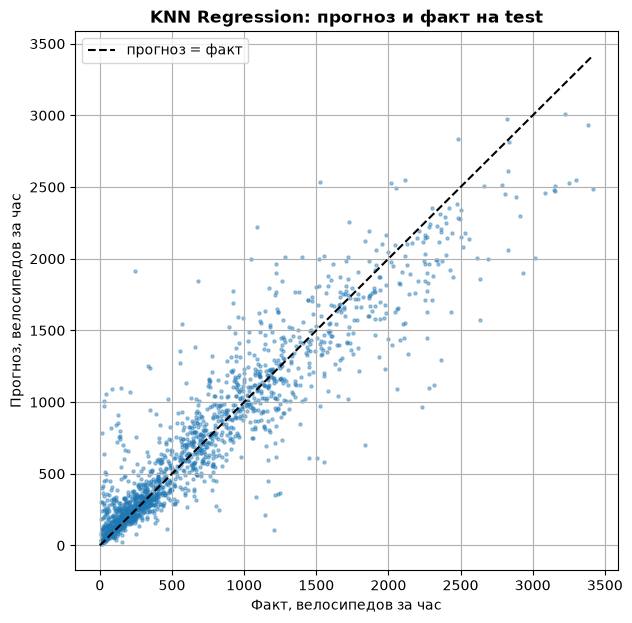

In [53]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test_c, y_pred_test_c, s=5, alpha=0.4)
lim = max(y_test_c.max().item(), y_pred_test_c.max().item())
plt.plot([0, lim], [0, lim], color='black', linestyle='--', label='прогноз = факт')
plt.title('KNN Regression: прогноз и факт на test')
plt.xlabel('Факт, велосипедов за час')
plt.ylabel('Прогноз, велосипедов за час')
plt.legend()
plt.show()

## 13. Вывод по части C

Я использовал тот же класс `KNN` в режиме `regression`, проверил `12` значений `k` для Euclidean и Manhattan со scaling и без него и выбрал конфигурацию по RMSE на validation.

| Модель | MAE test | RMSE test | R² test |
|---|---|---|---|
| KNN, Manhattan, со scaling, `k=5` | `154.4` | `250.4` | `0.8574` |
| KNN, Euclidean, со scaling, `k=5` | `161.1` | `262.3` | `0.8434` |
| KNN, Manhattan, без scaling, `k=9` | `312.5` | `444.0` | `0.5515` |
| KNN, Euclidean, без scaling, `k=9` | `334.2` | `469.4` | `0.4987` |
| Baseline, среднее train | `531.5` | `663.1` | `-0.0002` |
| Baseline, среднее train по часу | `418.3` | `540.6` | `0.3352` |

Итоговая модель: Manhattan, `k=5`, со scaling. Она снижает MAE на test в `3.4` раза и RMSE в `2.6` раза относительно константного baseline. Относительно среднего по часу RMSE ниже в `2.2` раза: час объясняет треть дисперсии спроса, остальное KNN берёт из погоды, сезона и типа дня. R² константного baseline чуть меньше нуля, потому что среднее `Count` в train `731.7` выше, чем в test `722.1`.

Scaling и расстояние:

- Без scaling R² падает с `0.8574` до `0.5515`. В расстоянии доминируют `Visibility` со стандартным отклонением `609` и `Humidity` с `20`, а час закодирован числами от `-1` до `1` и почти не влияет на выбор соседей, хотя по графику спрос сильно зависит от часа.
- Manhattan лучше Euclidean в обоих режимах, со scaling RMSE на test `250.4` против `262.3`. Причину я не проверял. Возможно, Euclidean сильнее штрафует большое расхождение по одному признаку, например по `Rainfall` или `Snowfall` с редкими большими значениями.

Выбор k:

- При `k=1` RMSE на validation `280.0` для Manhattan, при `k=5` минимум `231.9`, дальше рост до `318.5` при `k=101`.
- Малый `k` объясняется двумя причинами. Спрос резко меняется в течение дня, и большое число соседей смешивает разные часы. При случайном split в train лежат соседние часы того же дня с почти той же погодой, и ближайшие соседи оказываются почти копиями.
- Вероятно, второе завышает качество KNN. Split по дням я не проверял.

# Выводы

| Часть | Что сделал | Итог на test |
|---|---|---|
| A. Regularization | добавил L1, L2 и ElasticNet в Linear и Logistic Regression из лабораторной №1, подобрал λ по validation | небольшое улучшение: RMSE `870.1` → `853.8`, LogLoss `0.4550` → `0.4511`. L1 обнулил `12` весов из `29` и `7` из `26` без потери качества |
| B. KNN Classification | реализовал KNN, подобрал `k` и расстояние по validation, сравнил scaling | Euclidean, `k=9`, со scaling: Accuracy `0.9173`, Macro F1 `0.9297` |
| C. KNN Regression | тот же KNN в режиме regression, сравнил с двумя baseline | Manhattan, `k=5`, со scaling: RMSE `250.4` против `663.1` у среднего и `540.6` у среднего по часу |

Регуляризация уменьшила переобучение линейной регрессии на маленькой выборке и дала около `2%` по RMSE, а L1 вдобавок убрал лишние признаки. Для KNN важнее всего scaling: без него Macro F1 в части B падает до `0.7759`, R² в части C до `0.5515`.

Что можно улучшить:

- в части C разбить данные по дням, чтобы соседние часы не попадали в train и test одновременно.
- в KNN разрешать равенство голосов в пользу ближайшего соседа, сейчас выбирается класс с меньшим номером.
- в KNN взвешивать голоса соседей по расстоянию.
- ускорить подбор `k`: сейчас расстояния пересчитываются для каждого `k`, хотя достаточно один раз найти `max(k)` соседей и брать первые `k`.
- ускорить predict: сложность $O(n_{test} \cdot n_{train} \cdot d)$, для больших выборок нужен KD-tree или приближённый поиск соседей.